In [81]:
import pandas as pd
import numpy as np
import skimpy as sk
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import os
import shutil
import glob
import mlflow
import mlflow.sklearn
import joblib
import scipy.stats as ss
import statsmodels as ss
from itertools import combinations
from scipy.stats import wilcoxon, mannwhitneyu
from sklearn.metrics import root_mean_squared_error
from statsmodels.stats.multitest import multipletests


from sklearn.preprocessing import *
from sklearn.metrics import *
from sklearn.model_selection import *
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Lasso, Ridge
from sklearn.ensemble import AdaBoostRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor, VotingRegressor, StackingRegressor, ExtraTreesClassifier
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

In [44]:
train = pd.read_csv("data/processed/analysis/analysis_2015_2016.csv")
test = pd.read_csv("data/processed/analysis/analysis_2017_2018.csv")

In [45]:
sk.skim(train)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 5735   │ │ float64     │ 81    │                                                          │
│ │ Number of columns │ 93     │ │ bool        │ 9     │                                                          │
│ └───────────────────┴────────┘ │ string      │ 3     │                                                          │
│                                └─────────────┴───────┘                                                          │
│                                                    All null                                                     │
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓  │
│ ┃ column                                    ┃ NA                             ┃ NA %                          ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩  │
│ │                  SLQ320                   │                           5735 │                           100 │  │
│ │                  SLQ330                   │                           5735 │                           100 │  │
│ │                  SLD013                   │                           5735 │                           100 │  │
│ └───────────────────────────────────────────┴────────────────────────────────┴───────────────────────────────┘  │
│                                                     number                                                      │
│ ┏━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┓  │
│ ┃ column   ┃ NA   ┃ NA %     ┃ mean    ┃ sd      ┃ p0      ┃ p25      ┃ p50     ┃ p75      ┃ p100   ┃ hist   ┃  │
│ ┡━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━┩  │
│ │   SEQN   │    0 │        0 │   88680 │    2882 │   83730 │    86160 │   88670 │    91180 │  93700 │ ██████ │  │
│ │ RIDAGEYR │    0 │        0 │   48.05 │   18.43 │      18 │       32 │      48 │       63 │     80 │ █▇▇▇▇▇ │  │
│ │    _x    │      │          │         │         │         │          │         │          │        │        │  │
│ │ RIDSTATR │    0 │        0 │       2 │       0 │       2 │        2 │       2 │        2 │      2 │     █  │  │
│ │ RIAGENDR │    0 │        0 │   1.519 │  0.4997 │       1 │        1 │       2 │        2 │      2 │ ▇    █ │  │
│ │    _x    │      │          │         │         │         │          │         │          │        │        │  │
│ │ RIDRETH3 │    0 │        0 │   3.237 │   1.637 │       1 │        2 │       3 │        4 │      7 │ ▄▃█▅ ▄ │  │
│ │    _x    │      │          │         │         │         │          │         │          │        │        │  │
│ │ DMDEDUC2 │  261 │ 4.551002 │   3.442 │    1.31 │       1 │        3 │       4 │     4.75 │      9 │  ▆▆█▇  │  │
│ │    _x    │      │ 61551874 │         │         │         │          │         │          │        │        │  │
│ │          │      │        5 │         │         │         │          │         │          │        │        │  │
│ │ DMDMARTL │  261 │ 4.551002 │   2.629 │   2.367 │       1 │        1 │       1 │        5 │     77 │   █    │  │
│ │    _x    │      │ 61551874 │         │         │         │          │         │          │        │        │  │
│ │          │      │        5 │         │         │    

In [46]:
train

,SEQN,RIDAGEYR_x,RIDSTATR,RIAGENDR_x,RIDRETH3_x,DMDEDUC2_x,DMDMARTL_x,INDFMPIR_x,WTINT2YR,WTMEC2YR,...,DIQ160,DIQ170,DIQ180,midpoint_sin,midpoint_cos,DPQ_TOTAL,SBP_mean,DBP_mean,sleep_exposure_available,primary_candidate
0,83732.0,62.0,2.0,1.0,3.0,5.0,1.0,4.390000e+00,134671.370419,135629.507405,...,NaN,NaN,NaN,0.555570,0.831470,1.0,122.666667,65.333333,True,True
1,83733.0,53.0,2.0,1.0,3.0,3.0,3.0,1.320000e+00,24328.560239,25282.425927,...,2.0,2.0,2.0,0.707107,0.707107,2.0,140.000000,86.000000,True,True
2,83734.0,78.0,2.0,1.0,3.0,3.0,1.0,1.510000e+00,12400.008522,12575.838818,...,NaN,NaN,NaN,0.500000,0.866025,2.0,135.333333,45.333333,True,True
3,83735.0,56.0,2.0,2.0,3.0,5.0,6.0,5.000000e+00,102717.995647,102078.634508,...,1.0,1.0,1.0,0.659346,0.751840,13.0,134.000000,70.000000,True,True
4,83736.0,42.0,2.0,2.0,4.0,4.0,3.0,1.230000e+00,17627.674984,18234.736219,...,2.0,2.0,2.0,NaN,NaN,8.0,104.000000,60.000000,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5730,93695.0,76.0,2.0,2.0,3.0,3.0,2.0,1.430000e+00,58614.075016,66678.487176,...,2.0,2.0,1.0,0.659346,0.751840,3.0,111.333333,47.333333,True,True
5731,93696.0,26.0,2.0,1.0,3.0,5.0,1.0,2.990000e+00,122920.600828,132143.889434,...,2.0,1.0,1.0,0.195090,0.980785,NaN,116.000000,72.000000,True,False
5732,93697.0,80.0,2.0,2.0,3.0,4.0,2.0,2.970000e+00,49050.060431,52126.766231,...,2.0,2.0,1.0,0.707107,0.707107,NaN,148.000000,55.333333,True,True
5733,93700.0,35.0,2.0,1.0,3.0,1.0,1.0,5.397605e-79,42314.288108,43194.215112,...,2.0,2.0,2.0,0.965926,0.258819,NaN,104.666667,65.333333,True,True


In [47]:
sk.skim(test)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 5533   │ │ float64     │ 75    │                                                          │
│ │ Number of columns │ 89     │ │ bool        │ 9     │                                                          │
│ └───────────────────┴────────┘ │ string      │ 5     │                                                          │
│                                └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┓  │
│ ┃ column   ┃ NA   ┃ NA %     ┃ mean     ┃ sd     ┃ p0       ┃ p25     ┃ p50      ┃ p75     ┃ p100   ┃ hist   ┃  │
│ ┡━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━┩  │
│ │   SEQN   │    0 │        0 │    98280 │   2686 │    93700 │   95940 │    98260 │  100600 │ 103000 │ ██████ │  │
│ │ RIDAGEYR │    0 │        0 │    49.82 │  18.65 │       18 │      33 │       51 │      65 │     80 │ ▇▆▆▇█▇ │  │
│ │    _x    │      │          │          │        │          │         │          │         │        │        │  │
│ │ RIDSTATR │    0 │        0 │        2 │      0 │        2 │       2 │        2 │       2 │      2 │     █  │  │
│ │ RIAGENDR │    0 │        0 │    1.517 │ 0.4998 │        1 │       1 │        2 │       2 │      2 │ ▇    █ │  │
│ │    _x    │      │          │          │        │          │         │          │         │        │        │  │
│ │ RIDRETH3 │    0 │        0 │    3.504 │  1.655 │        1 │       3 │        3 │       4 │      7 │ ▃▂█▅ ▅ │  │
│ │    _x    │      │          │          │        │          │         │          │         │        │        │  │
│ │ DMDEDUC2 │  268 │ 4.843665 │    3.527 │  1.239 │        1 │       3 │        4 │       4 │      9 │  ▅▆█▆  │  │
│ │    _x    │      │ 28104102 │          │        │          │         │          │         │        │        │  │
│ │          │      │        7 │          │        │          │         │          │         │        │        │  │
│ │ DMDMARTL │  268 │ 4.843665 │    2.665 │  2.955 │        1 │       1 │        2 │       5 │     77 │   █    │  │
│ │    _x    │      │ 28104102 │          │        │          │         │          │         │        │        │  │
│ │          │      │        7 │          │        │          │         │          │         │        │        │  │
│ │ INDFMPIR │  734 │ 13.26585 │    2.521 │  1.609 │ 5.398e-7 │    1.18 │     2.08 │    4.06 │      5 │ ▅█▆▄▃█ │  │
│ │    _x    │      │ 93891198 │          │        │        9 │         │          │         │        │        │  │
│ │          │      │       27 │          │        │          │         │          │         │        │        │  │
│ │ WTINT2YR │    0 │        0 │    42270 │  49050 │     4363 │   15010 │    25070 │   45730 │ 433100 │   █▁   │  │
│ │ WTMEC2YR │    0 │        0 │    44670 │  51360 │     4580 │   15820 │    26410 │   48910 │ 419800 │   █▁   │  │
│ │ SDMVPSU  │    0 │        0 │    1.517 │ 0.4998 │        1 │       1 │        2 │       2 │      2 │ ▇    █ │  │
│ │ SDMVSTRA │    0 │        0 │      141 │  4.233 │      134 │     137 │      141 │     145 │    148 │ █▅▅█▅▇ │  │
│ │  SLD012  │   44 │ 0.795228 │    7.621 │  1.678 │    

In [48]:
train

,SEQN,RIDAGEYR_x,RIDSTATR,RIAGENDR_x,RIDRETH3_x,DMDEDUC2_x,DMDMARTL_x,INDFMPIR_x,WTINT2YR,WTMEC2YR,...,DIQ160,DIQ170,DIQ180,midpoint_sin,midpoint_cos,DPQ_TOTAL,SBP_mean,DBP_mean,sleep_exposure_available,primary_candidate
0,83732.0,62.0,2.0,1.0,3.0,5.0,1.0,4.390000e+00,134671.370419,135629.507405,...,NaN,NaN,NaN,0.555570,0.831470,1.0,122.666667,65.333333,True,True
1,83733.0,53.0,2.0,1.0,3.0,3.0,3.0,1.320000e+00,24328.560239,25282.425927,...,2.0,2.0,2.0,0.707107,0.707107,2.0,140.000000,86.000000,True,True
2,83734.0,78.0,2.0,1.0,3.0,3.0,1.0,1.510000e+00,12400.008522,12575.838818,...,NaN,NaN,NaN,0.500000,0.866025,2.0,135.333333,45.333333,True,True
3,83735.0,56.0,2.0,2.0,3.0,5.0,6.0,5.000000e+00,102717.995647,102078.634508,...,1.0,1.0,1.0,0.659346,0.751840,13.0,134.000000,70.000000,True,True
4,83736.0,42.0,2.0,2.0,4.0,4.0,3.0,1.230000e+00,17627.674984,18234.736219,...,2.0,2.0,2.0,NaN,NaN,8.0,104.000000,60.000000,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5730,93695.0,76.0,2.0,2.0,3.0,3.0,2.0,1.430000e+00,58614.075016,66678.487176,...,2.0,2.0,1.0,0.659346,0.751840,3.0,111.333333,47.333333,True,True
5731,93696.0,26.0,2.0,1.0,3.0,5.0,1.0,2.990000e+00,122920.600828,132143.889434,...,2.0,1.0,1.0,0.195090,0.980785,NaN,116.000000,72.000000,True,False
5732,93697.0,80.0,2.0,2.0,3.0,4.0,2.0,2.970000e+00,49050.060431,52126.766231,...,2.0,2.0,1.0,0.707107,0.707107,NaN,148.000000,55.333333,True,True
5733,93700.0,35.0,2.0,1.0,3.0,1.0,1.0,5.397605e-79,42314.288108,43194.215112,...,2.0,2.0,2.0,0.965926,0.258819,NaN,104.666667,65.333333,True,True


In [49]:
test

,SEQN,RIDAGEYR_x,RIDSTATR,RIAGENDR_x,RIDRETH3_x,DMDEDUC2_x,DMDMARTL_x,INDFMPIR_x,WTINT2YR,WTMEC2YR,...,DIQ160,DIQ170,DIQ180,midpoint_sin,midpoint_cos,DPQ_TOTAL,SBP_mean,DBP_mean,sleep_exposure_available,primary_candidate
0,93705.0,66.0,2.0,2.0,4.0,2.0,3.0,0.82,8614.571172,8338.419786,...,2.0,2.0,1.0,0.707107,0.707107,NaN,200.000000,68.000000,True,True
1,93706.0,18.0,2.0,1.0,6.0,NaN,NaN,NaN,8548.632619,8723.439814,...,2.0,2.0,2.0,0.946930,0.321439,NaN,111.333333,73.333333,True,True
2,93708.0,66.0,2.0,2.0,6.0,1.0,1.0,1.63,13329.450589,14372.488765,...,NaN,2.0,1.0,0.608761,0.793353,NaN,142.000000,76.000000,True,True
3,93709.0,75.0,2.0,2.0,4.0,4.0,2.0,0.41,12043.388271,12277.556662,...,1.0,2.0,1.0,0.500000,0.866025,NaN,118.666667,66.666667,True,True
4,93711.0,56.0,2.0,1.0,6.0,5.0,1.0,5.00,11178.260106,12390.919724,...,2.0,2.0,1.0,0.382683,0.923880,2.0,101.333333,66.666667,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5528,102949.0,33.0,2.0,1.0,3.0,3.0,6.0,1.01,29334.650205,30287.188731,...,2.0,2.0,2.0,0.659346,0.751840,NaN,122.000000,76.666667,True,True
5529,102952.0,70.0,2.0,2.0,6.0,3.0,1.0,0.95,16896.276203,18338.711104,...,NaN,2.0,2.0,0.659346,0.751840,NaN,139.333333,73.333333,True,True
5530,102953.0,42.0,2.0,1.0,1.0,3.0,4.0,NaN,61630.380013,63661.951573,...,1.0,2.0,1.0,0.258819,0.965926,4.0,120.666667,75.333333,True,True
5531,102954.0,41.0,2.0,2.0,4.0,5.0,5.0,1.18,17160.895269,17694.783346,...,2.0,2.0,1.0,0.500000,0.866025,NaN,116.000000,70.666667,True,True


In [50]:
train.isnull().sum()

SEQN                           0
RIDAGEYR_x                     0
RIDSTATR                       0
RIAGENDR_x                     0
RIDRETH3_x                     0
                            ... 
DPQ_TOTAL                   2176
SBP_mean                     164
DBP_mean                     164
sleep_exposure_available       0
primary_candidate              0
Length: 93, dtype: int64

In [51]:
test.isnull().sum()

SEQN                           0
RIDAGEYR_x                     0
RIDSTATR                       0
RIAGENDR_x                     0
RIDRETH3_x                     0
                            ... 
DPQ_TOTAL                   2189
SBP_mean                     283
DBP_mean                     283
sleep_exposure_available       0
primary_candidate              0
Length: 89, dtype: int64

## EDA

In [52]:
os.makedirs("Visualization", exist_ok=True)

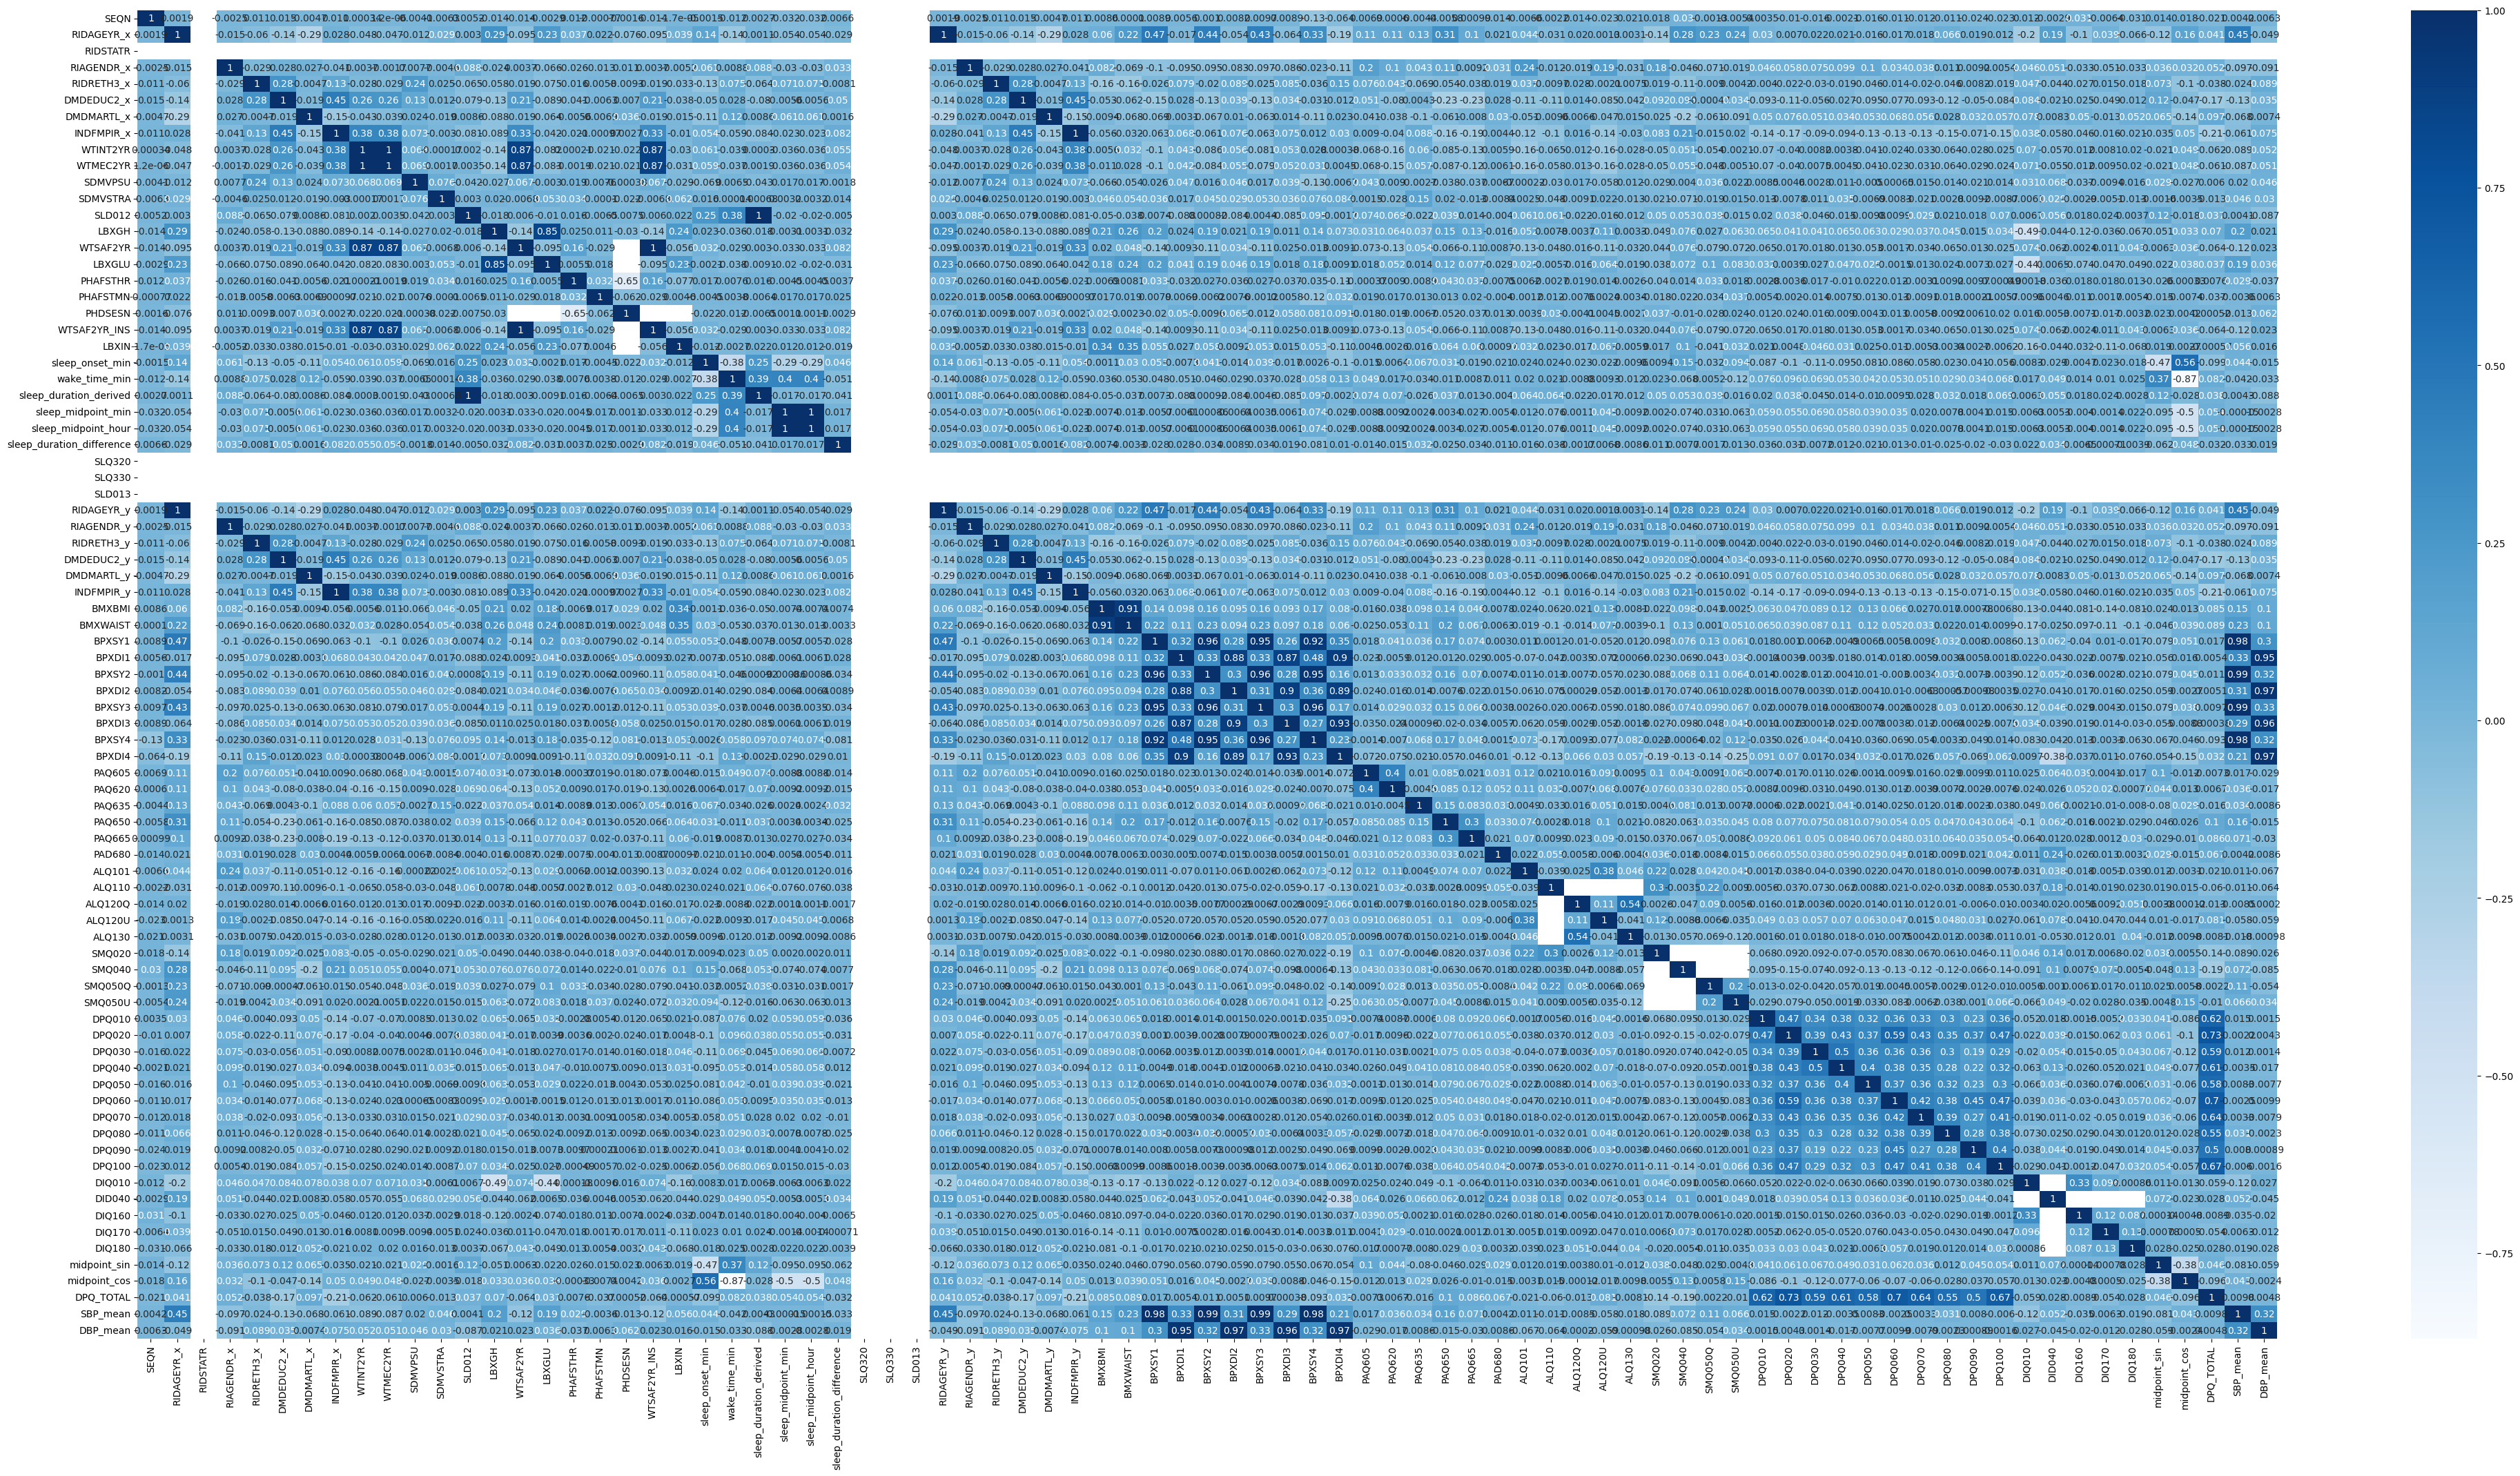

In [53]:
corr = train.select_dtypes(include="number").corr(method="pearson")

plt.figure(figsize=(50, 25))
sns.heatmap(corr, annot=True, cmap="Blues")
plt.savefig("Visualization/Correlation.png")
plt.show()

/tmp/ipykernel_6726/2350962625.py:1: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(train)


<Axes: ylabel='Density'>

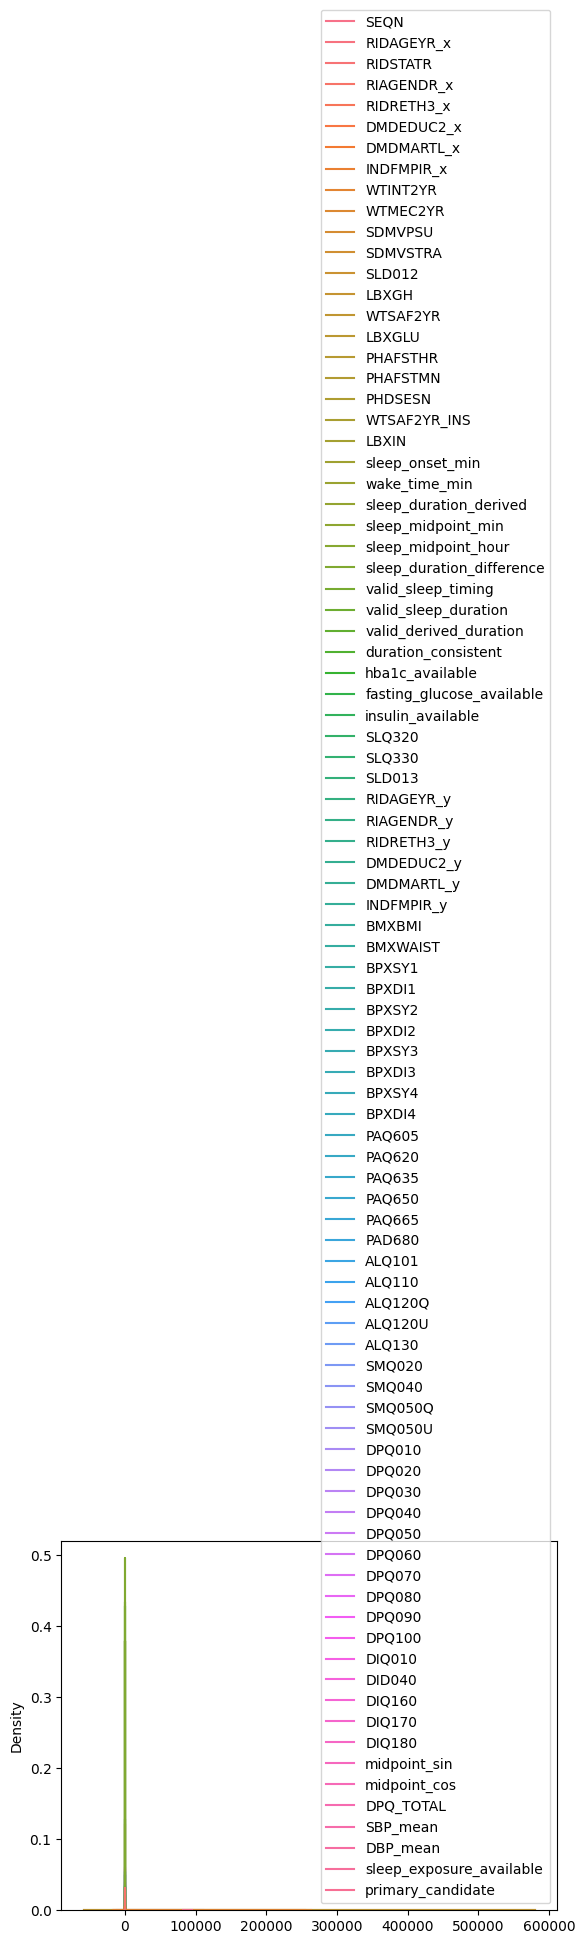

In [54]:
sns.kdeplot(train)

<Axes: >

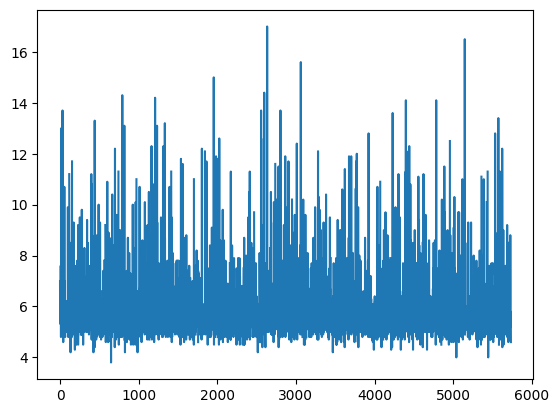

In [55]:
train["LBXGH"].plot()

## Feature Engineering

In [56]:
def engineer_features(df):
    df = df.copy()

    # Resolve duplicated demographic columns.
    demographic_cols = [
        "RIDAGEYR", "RIAGENDR", "RIDRETH3",
        "DMDEDUC2", "DMDMARTL", "INDFMPIR",
    ]

    for col in demographic_cols:
        x_col, y_col = f"{col}_x", f"{col}_y"

        if x_col in df.columns and y_col in df.columns:
            x, y = df[x_col], df[y_col]
            comparable = x.notna() & y.notna()

            if not x[comparable].equals(y[comparable]):
                raise ValueError(
                    f"Conflicting demographic columns: {x_col}, {y_col}"
                )

            df[col] = x.combine_first(y)
            df.drop(columns=[x_col, y_col], inplace=True)

        elif x_col in df.columns:
            df.rename(columns={x_col: col}, inplace=True)
        elif y_col in df.columns:
            df.rename(columns={y_col: col}, inplace=True)

    # Circular encoding of sleep midpoint.
    midpoint = pd.to_numeric(
        df["sleep_midpoint_min"], errors="coerce"
    )
    valid_midpoint = midpoint.between(0, 1439)
    angle = 2 * np.pi * midpoint / 1440

    df["midpoint_sin"] = np.where(
        valid_midpoint, np.sin(angle), np.nan
    )
    df["midpoint_cos"] = np.where(
        valid_midpoint, np.cos(angle), np.nan
    )

    # Sleep duration features.
    duration = pd.to_numeric(
        df["sleep_duration_derived"], errors="coerce"
    )
    df["sleep_duration_valid"] = duration.where(
        duration.between(3, 14)
    )
    df["sleep_duration_centered"] = (
        df["sleep_duration_valid"] - 7
    )
    df["sleep_duration_centered_sq"] = (
        df["sleep_duration_centered"] ** 2
    )

    # Nonlinear age features.
    age = pd.to_numeric(df["RIDAGEYR"], errors="coerce")
    df["age_centered"] = age - 45
    df["age_centered_sq"] = df["age_centered"] ** 2

    # Timing × duration interaction features.
    df["midpoint_sin_x_duration"] = (
        df["midpoint_sin"] * df["sleep_duration_centered"]
    )
    df["midpoint_cos_x_duration"] = (
        df["midpoint_cos"] * df["sleep_duration_centered"]
    )

    # Final imputation: numeric columns only.
    # Target and survey/design identifiers are left untouched.
    exclude = {
        "LBXGH", "SEQN", "SDMVPSU", "SDMVSTRA",
        "WTINT2YR", "WTMEC2YR",
    }
    numeric_cols = [
        c for c in df.select_dtypes(include="number").columns
        if c not in exclude
    ]

    for col in numeric_cols:
        median_value = df[col].median()
        if pd.isna(median_value):
            mean_value = df[col].mean()
            if pd.notna(mean_value):
                df[col] = df[col].fillna(mean_value)
        else:
            df[col] = df[col].fillna(median_value)

    return df



train = engineer_features(train).drop(columns=['ALQ101', 'ALQ110', 'ALQ120Q', 'ALQ120U'])
test = engineer_features(test)

In [57]:
train.columns

Index(['SEQN', 'RIDSTATR', 'WTINT2YR', 'WTMEC2YR', 'SDMVPSU', 'SDMVSTRA',
       'SLQ300', 'SLQ310', 'SLD012', 'LBXGH', 'WTSAF2YR', 'LBXGLU', 'PHAFSTHR',
       'PHAFSTMN', 'PHDSESN', 'WTSAF2YR_INS', 'LBXIN', 'sleep_onset_min',
       'wake_time_min', 'sleep_duration_derived', 'sleep_midpoint_min',
       'sleep_midpoint_hour', 'sleep_duration_difference',
       'valid_sleep_timing', 'valid_sleep_duration', 'valid_derived_duration',
       'duration_consistent', 'hba1c_available', 'fasting_glucose_available',
       'insulin_available', 'cycle', 'SLQ320', 'SLQ330', 'SLD013', 'BMXBMI',
       'BMXWAIST', 'BPXSY1', 'BPXDI1', 'BPXSY2', 'BPXDI2', 'BPXSY3', 'BPXDI3',
       'BPXSY4', 'BPXDI4', 'PAQ605', 'PAQ620', 'PAQ635', 'PAQ650', 'PAQ665',
       'PAD680', 'ALQ130', 'SMQ020', 'SMQ040', 'SMQ050Q', 'SMQ050U', 'DPQ010',
       'DPQ020', 'DPQ030', 'DPQ040', 'DPQ050', 'DPQ060', 'DPQ070', 'DPQ080',
       'DPQ090', 'DPQ100', 'DIQ010', 'DID040', 'DIQ160', 'DIQ170', 'DIQ180',
       'midpoint_s

In [58]:
test.columns

Index(['SEQN', 'RIDSTATR', 'WTINT2YR', 'WTMEC2YR', 'SDMVPSU', 'SDMVSTRA',
       'SLQ300', 'SLQ310', 'SLD012', 'LBXGH', 'WTSAF2YR', 'LBXGLU', 'PHAFSTHR',
       'PHAFSTMN', 'PHDSESN', 'WTSAF2YR_INS', 'LBXIN', 'sleep_onset_min',
       'wake_time_min', 'sleep_duration_derived', 'sleep_midpoint_min',
       'sleep_midpoint_hour', 'sleep_duration_difference',
       'valid_sleep_timing', 'valid_sleep_duration', 'valid_derived_duration',
       'duration_consistent', 'hba1c_available', 'fasting_glucose_available',
       'insulin_available', 'cycle', 'SLQ320', 'SLQ330', 'SLD013', 'BMXBMI',
       'BMXWAIST', 'BPXSY1', 'BPXDI1', 'BPXSY2', 'BPXDI2', 'BPXSY3', 'BPXDI3',
       'BPXSY4', 'BPXDI4', 'PAQ605', 'PAQ620', 'PAQ635', 'PAQ650', 'PAQ665',
       'PAD680', 'ALQ130', 'SMQ020', 'SMQ040', 'SMQ050Q', 'SMQ050U', 'DPQ010',
       'DPQ020', 'DPQ030', 'DPQ040', 'DPQ050', 'DPQ060', 'DPQ070', 'DPQ080',
       'DPQ090', 'DPQ100', 'DIQ010', 'DID040', 'DIQ160', 'DIQ170', 'DIQ180',
       'midpoint_s

In [59]:
train["LBXGH"]

0       7.0
1       5.5
2       5.8
3       5.6
4       5.6
       ... 
5730    5.6
5731    NaN
5732    5.7
5733    5.2
5734    4.6
Name: LBXGH, Length: 5735, dtype: float64

In [60]:
set(train.columns.tolist()).difference(test.columns.tolist())

set()

## Modelling

In [61]:
train["LBXGH"] = pd.to_numeric(train["LBXGH"], errors="coerce")

In [62]:
EXCLUDE = [
    # Outcome availability / selection
    "hba1c_available",
    "sleep_exposure_available",
    "primary_candidate",

    # Redundant duration representation
    "valid_derived_duration",

    # Duplicate survey-weight representation
    "WTSAF2YR_INS",

    # Identifiers / survey design
    "SEQN",
    "SDMVPSU",
    "SDMVSTRA",
    "WTINT2YR",
    "WTMEC2YR",
    "WTSAF2YR",
]

# Optional: exclude these for a demographics + sleep-focused
# sensitivity analysis rather than the main model by default.
GLYCEMIC_EXCLUSIONS = ["LBXGLU", "DIQ010"]

model_data = train.copy()
model_data["LBXGH"] = pd.to_numeric(
    model_data["LBXGH"], errors="coerce"
)
model_data = model_data.dropna(subset=["LBXGH"]).copy()

drop_cols = [
    col for col in EXCLUDE
    if col in model_data.columns
]

X = model_data.drop(
    columns=["LBXGH"] + drop_cols,
    errors="ignore",
)
y = model_data["LBXGH"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [63]:
print("Missing HbA1c before filtering:", train["LBXGH"].isna().sum())

Missing HbA1c before filtering: 294


In [64]:
Y_COL = "LBXGH"

COVARIATES = [
    "sleep_duration_valid",
    "RIDAGEYR",
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "INDFMPIR",
]

required = [
    Y_COL,
    "sleep_midpoint_min",
    *COVARIATES,
]

missing = [c for c in required if c not in train.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

causal_train = train.loc[
    train[Y_COL].notna()
    & train["sleep_midpoint_min"].between(0, 1439)
    & train["sleep_duration_valid"].between(3, 14)
].copy()

causal_test = test.loc[
    test[Y_COL].notna()
    & test["sleep_midpoint_min"].between(0, 1439)
    & test["sleep_duration_valid"].between(3, 14)
].copy()

print("Causal training sample:", causal_train.shape)
print("Temporal test sample:", causal_test.shape)

Causal training sample: (5441, 90)
Temporal test sample: (5261, 90)


In [65]:
midpoint = causal_train["sleep_midpoint_min"].astype(float)
hours = midpoint / 60

for center in [2, 3]:
    # Circular distance from the target clock time, in hours.
    distance = ((hours - center + 12) % 24) - 12
    nearby = distance.abs() <= 0.5

    print(
        f"Within 30 minutes of {center}:00:",
        int(nearby.sum()),
        "participants"
    )

Within 30 minutes of 2:00: 2144 participants
Within 30 minutes of 3:00: 1923 participants


In [66]:
#Propensity Model and general causal settings
Y_COL = "LBXGH"
MIDPOINT_COL = "sleep_midpoint_min"

# Prespecified adjustment variables.
# Sleep duration is explicitly included.
NUMERIC = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

CATEGORICAL = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()
COVARIATES = NUMERIC + CATEGORICAL

# Define the two midpoint groups

df = causal_train.copy()

minutes = pd.to_numeric(df[MIDPOINT_COL], errors="coerce")
hours = minutes / 60

# Circular distance, in hours.
dist_2 = np.abs(((hours - 2 + 12) % 24) - 12)
dist_3 = np.abs(((hours - 3 + 12) % 24) - 12)

near_2 = dist_2 <= 0.5
near_3 = dist_3 <= 0.5

# Exclude all other midpoint times.
keep = (
    df[Y_COL].notna()
    & df["sleep_duration_valid"].between(3, 14)
    & (near_2 | near_3)
)

df = df.loc[keep].copy()
df["A"] = near_3.loc[df.index].astype(int)

# Remove missing outcome, invalid duration, and missing exposure.
# Feature imputation is learned separately inside each fold.
y = df[Y_COL].astype(float).to_numpy()
A = df["A"].to_numpy()
X = df[COVARIATES].copy()

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
    ]), NUMERIC),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        )),
    ]), CATEGORICAL),
])



propensity_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        C=1.0,
    )),
])

In [67]:
#Models 

ridge = Pipeline([
    ("preprocessor", preprocessor),
    ("scaler", StandardScaler()),
    ("model", Ridge(
        alpha=10.0,
        solver="lsqr",
        tol=1e-4
    ))
])

extra_trees = Pipeline([
    ("preprocessor", preprocessor),
    ("transformer", QuantileTransformer(
        n_quantiles=500,
        output_distribution="normal",
        subsample=10000,
        random_state=42
    )),
    ("model", ExtraTreesRegressor(
        n_estimators=300,
        criterion="squared_error",
        max_depth=None,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features=0.8,
        bootstrap=False,
        n_jobs=-1,
        random_state=42
    ))
])


hist_gb = Pipeline([
    ("preprocessor", preprocessor),
    ("transformer", QuantileTransformer(
        n_quantiles=500,
        output_distribution="normal",
        subsample=10000,
        random_state=42
    )),
    ("model", HistGradientBoostingRegressor(
        loss="squared_error",
        learning_rate=0.05,
        max_iter=200,
        max_leaf_nodes=15,
        max_depth=None,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42
    ))
])

xgb = Pipeline([
    ("preprocessor", preprocessor),
    ("transformer", QuantileTransformer(
        n_quantiles=500,
        output_distribution="normal",
        subsample=10000,
        random_state=42
    )),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        n_estimators=500,
        learning_rate=0.03,
        max_depth=4,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=5.0,
        gamma=0.0,
        tree_method="hist",
        n_jobs=-1,
        random_state=42
    ))
])

lgb = Pipeline([
    ("preprocessor", preprocessor),
    ("transformer", QuantileTransformer(
        n_quantiles=500,
        output_distribution="normal",
        subsample=10000,
        random_state=42
    )),
    ("model", LGBMRegressor(
        objective="regression",
        n_estimators=500,
        learning_rate=0.03,
        num_leaves=15,
        max_depth=-1,
        min_child_samples=30,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=5.0,
        verbosity=-1,
        n_jobs=-1,
        random_state=42
    ))
])

catboost = Pipeline([
    ("preprocessor", preprocessor),
    ("transformer", QuantileTransformer(
        n_quantiles=500,
        output_distribution="normal",
        subsample=10000,
        random_state=42
    )),
    ("model", CatBoostRegressor(
        iterations=600,
        learning_rate=0.03,
        depth=6,
        loss_function="RMSE",
        l2_leaf_reg=5.0,
        random_strength=1.0,
        bootstrap_type="Bayesian",
        bagging_temperature=1.0,
        verbose=0,
        thread_count=-1,
        random_seed=42
    ))
])

In [68]:
os.makedirs("outputs/learning_curves", exist_ok=True)

models = {
    "RidgeRegression": ridge,
    "HistGradientBoostingRegressor": hist_gb,
    "ExtraTreesRegressor": extra_trees,
    "XGBoostRegressor": xgb,
    "LGBMRegressor": lgb,
    "CatBoostRegressor": catboost,
}

mlflow.set_experiment("Model DML Experiments")

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42,
)

train_sizes = np.linspace(0.2, 1.0, 5)

results = []

# --------------------------------------------------
# EXPERIMENT LOOP
# --------------------------------------------------

for name, model in models.items():

    print(f"\n{'=' * 60}")
    print(f"Training: {name}")
    print(f"{'=' * 60}")

    with mlflow.start_run(run_name=name):

        mlflow.log_param("model_name", name)
        mlflow.log_param("random_state", 42)
        mlflow.log_param("cv_folds", 3)

        # Log model hyperparameters
        for param, value in model.get_params(deep=True).items():
            if isinstance(value, (str, int, float, bool, type(None))):
                mlflow.log_param(
                    param,
                    str(value)[:500] if value is not None else "None"
                )

        # ------------------------------------------
        # FIT MODEL
        # ------------------------------------------

        fitted_model = clone(model)
        fitted_model.fit(X_train, y_train)

        # ------------------------------------------
        # PREDICTIONS
        # ------------------------------------------

        y_train_pred = fitted_model.predict(X_train)
        y_test_pred = fitted_model.predict(X_test)

        # ------------------------------------------
        # REGRESSION METRICS
        # ------------------------------------------

        train_rmse = np.sqrt(
            mean_squared_error(y_train, y_train_pred)
        )

        test_rmse = np.sqrt(
            mean_squared_error(y_test, y_test_pred)
        )

        train_mae = mean_absolute_error(
            y_train, y_train_pred
        )

        test_mae = mean_absolute_error(
            y_test, y_test_pred
        )

        train_r2 = r2_score(
            y_train, y_train_pred
        )

        test_r2 = r2_score(
            y_test, y_test_pred
        )

        metrics = {
            "train_RMSE": train_rmse,
            "test_RMSE": test_rmse,
            "train_MAE": train_mae,
            "test_MAE": test_mae,
            "train_R2": train_r2,
            "test_R2": test_r2,
            "RMSE_gap": test_rmse - train_rmse,
        }

        mlflow.log_metrics(metrics)

        # ------------------------------------------
        # LEARNING CURVE
        # ------------------------------------------

        print("Computing learning curve...")

        sizes, train_scores, cv_scores = learning_curve(
            estimator=clone(model),
            X=X_train,
            y=y_train,
            train_sizes=train_sizes,
            cv=cv,
            scoring="neg_root_mean_squared_error",
            n_jobs=1,
            shuffle=True,
            random_state=42,
            error_score="raise",
        )

        # sklearn returns negative RMSE for this scorer.
        train_rmse_curve = -train_scores
        cv_rmse_curve = -cv_scores

        train_mean = train_rmse_curve.mean(axis=1)
        train_std = train_rmse_curve.std(axis=1)

        cv_mean = cv_rmse_curve.mean(axis=1)
        cv_std = cv_rmse_curve.std(axis=1)

        fig, ax = plt.subplots(figsize=(9, 6))

        ax.plot(
            sizes,
            train_mean,
            marker="o",
            label="Training RMSE",
        )

        ax.fill_between(
            sizes,
            train_mean - train_std,
            train_mean + train_std,
            alpha=0.15,
        )

        ax.plot(
            sizes,
            cv_mean,
            marker="o",
            label="Cross-validation RMSE",
        )

        ax.fill_between(
            sizes,
            cv_mean - cv_std,
            cv_mean + cv_std,
            alpha=0.15,
        )

        ax.set_title(f"Learning Curve — {name}")
        ax.set_xlabel("Number of Training Samples")
        ax.set_ylabel("RMSE (lower is better)")
        ax.legend()
        ax.grid(True, alpha=0.3)

        fig.tight_layout()

        plot_path = (
            f"outputs/learning_curves/{name}_learning_curve.png"
        )

        fig.savefig(plot_path, dpi=300, bbox_inches="tight")
        plt.close(fig)

        mlflow.log_artifact(
            plot_path,
            artifact_path="learning_curves",
        )

        # ------------------------------------------
        # LOG MODEL
        # ------------------------------------------

        mlflow.sklearn.log_model(
            sk_model=fitted_model,
            artifact_path="model",
        )

        # ------------------------------------------
        # SAVE RESULTS
        # ------------------------------------------

        results.append({
            "Model": name,
            **metrics,
            "Best_CV_RMSE": cv_mean[-1],
        })

        print(f"Train RMSE : {train_rmse:.4f}")
        print(f"Test RMSE  : {test_rmse:.4f}")
        print(f"Train MAE  : {train_mae:.4f}")
        print(f"Test MAE   : {test_mae:.4f}")
        print(f"Train R²   : {train_r2:.4f}")
        print(f"Test R²    : {test_r2:.4f}")
        print(f"RMSE Gap   : {test_rmse - train_rmse:.4f}")
        print(f"Learning curve saved: {plot_path}")



Training: RidgeRegression


/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is nee

Computing learning curve...


/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is nee

Train RMSE : 0.7819
Test RMSE  : 0.8144
Train MAE  : 0.4672
Test MAE   : 0.4852
Train R²   : 0.5501
Test R²    : 0.5116
RMSE Gap   : 0.0325
Learning curve saved: outputs/learning_curves/RidgeRegression_learning_curve.png

Training: HistGradientBoostingRegressor


...

Train RMSE : 0.4746
Test RMSE  : 0.8239
Train MAE  : 0.3057
Test MAE   : 0.4412
Train R²   : 0.8342
Test R²    : 0.5001
RMSE Gap   : 0.3493
Learning curve saved: outputs/learning_curves/LGBMRegressor_learning_curve.png

Training: CatBoostRegressor


/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Computing learning curve...


/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is nee

Train RMSE : 0.5429
Test RMSE  : 0.7886
Train MAE  : 0.3468
Test MAE   : 0.4305
Train R²   : 0.7831
Test R²    : 0.5421
RMSE Gap   : 0.2457
Learning curve saved: outputs/learning_curves/CatBoostRegressor_learning_curve.png


In [69]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Missing training targets:", y_train.isna().sum())
print("Missing testing targets:", y_test.isna().sum())

Training shape: (4352, 78)
Testing shape: (1089, 78)
Missing training targets: 0
Missing testing targets: 0


In [70]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="test_RMSE",
    ascending=True,
).reset_index(drop=True)

results_df.to_csv(
    "outputs/model_comparison.csv",
    index=False,
)

print("\nMODEL COMPARISON")
print(results_df.to_string(index=False))


MODEL COMPARISON
                        Model  train_RMSE  test_RMSE  train_MAE  test_MAE  train_R2  test_R2  RMSE_gap  Best_CV_RMSE
            CatBoostRegressor    0.542879   0.788574   0.346802  0.430534  0.783094 0.542115  0.245695      0.718015
HistGradientBoostingRegressor    0.574168   0.803931   0.356434  0.435227  0.757371 0.524106  0.229764      0.731012
             XGBoostRegressor    0.492454   0.806978   0.314739  0.436971  0.821518 0.520492  0.314525      0.722970
              RidgeRegression    0.781862   0.814408   0.467167  0.485210  0.550091 0.511622  0.032546      0.823386
                LGBMRegressor    0.474624   0.823928   0.305692  0.441192  0.834208 0.500138  0.349304      0.735680
          ExtraTreesRegressor    0.429399   0.827137   0.223880  0.444673  0.864298 0.496236  0.397738      0.759425


In [71]:
data = train.copy()

data["LBXGH"] = pd.to_numeric(data["LBXGH"], errors="coerce")
data = data.loc[data["LBXGH"].notna()].copy()

X = data.drop(columns=["LBXGH"])
y = data["LBXGH"]

# 1. Suspicious column names
keywords = [
    "lbxgh", "hba1c", "a1c", "glycohemoglobin",
    "target", "outcome", "prediction", "label"
]

suspicious_cols = [
    col for col in X.columns
    if any(term in col.lower() for term in keywords)
]

print("Suspicious columns:", suspicious_cols)

# 2. Exact duplicate columns
duplicate_cols = []
for i, col1 in enumerate(X.columns):
    for col2 in X.columns[i + 1:]:
        if X[col1].equals(X[col2]):
            duplicate_cols.append((col1, col2))

print("\nExact duplicate feature pairs:")
print(duplicate_cols)

# 3. Features highly correlated with HbA1c
numeric_X = X.select_dtypes(include="number")
correlations = numeric_X.corrwith(y).dropna()

print("\nLargest absolute correlations with LBXGH:")
print(
    correlations.abs()
    .sort_values(ascending=False)
    .head(20)
    .to_frame("absolute_correlation")
    .join(correlations.rename("signed_correlation"))
)

# 4. Check target integrity
print("\nTarget checks:")
print("Rows:", len(data))
print("Missing target:", y.isna().sum())
print("Target range:", y.min(), "to", y.max())
print("Target unique values:", y.nunique())

assert y.notna().all()
assert "LBXGH" not in X.columns

Suspicious columns: ['hba1c_available']

Exact duplicate feature pairs:
[('WTSAF2YR', 'WTSAF2YR_INS'), ('valid_sleep_duration', 'valid_derived_duration'), ('valid_sleep_duration', 'sleep_exposure_available'), ('valid_sleep_duration', 'primary_candidate'), ('valid_derived_duration', 'sleep_exposure_available'), ('valid_derived_duration', 'primary_candidate'), ('SLQ320', 'SLQ330'), ('SLQ320', 'SLD013'), ('SLQ330', 'SLD013'), ('sleep_exposure_available', 'primary_candidate')]

Largest absolute correlations with LBXGH:
              absolute_correlation  signed_correlation
LBXGLU                    0.617673            0.617673
DIQ010                    0.492966           -0.492966
age_centered              0.294082            0.294082
RIDAGEYR                  0.294082            0.294082
BMXWAIST                  0.245425            0.245425
BMXBMI                    0.209541            0.209541
SBP_mean                  0.195708            0.195708
BPXSY1                    0.195333     

/home/voltsy/.local/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/voltsy/.local/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


## Statistical Test

In [72]:
test_predictions = {}
test_targets = None

test_predictions[name] = np.asarray(y_test_pred, dtype=float)
test_targets = np.asarray(y_test, dtype=float).ravel()

In [73]:

# --------------------------------------------------
# RECOVER PREDICTIONS FOR ALL MODELS
# --------------------------------------------------

test_predictions = {}
test_targets = np.asarray(y_test, dtype=float).ravel()

for name, model in models.items():

    print(f"Generating test predictions: {name}")

    fitted_model = clone(model)
    fitted_model.fit(X_train, y_train)

    test_predictions[name] = np.asarray(
        fitted_model.predict(X_test),
        dtype=float
    ).ravel()

# --------------------------------------------------
# VALIDATE
# --------------------------------------------------

assert len(test_predictions) == len(models)

for name, pred in test_predictions.items():
    assert len(pred) == len(test_targets), (
        f"Length mismatch for {name}: "
        f"{len(pred)} vs {len(test_targets)}"
    )
    assert np.isfinite(pred).all(), (
        f"Non-finite predictions found for {name}"
    )

print("\nPrediction recovery complete.")
print("Models:", list(test_predictions.keys()))
print("Test observations:", len(test_targets))


Generating test predictions: RidgeRegression


/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Generating test predictions: HistGradientBoostingRegressor


/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Generating test predictions: ExtraTreesRegressor


...

Generating test predictions: LGBMRegressor


/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Generating test predictions: CatBoostRegressor


/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(



Prediction recovery complete.
Models: ['RidgeRegression', 'HistGradientBoostingRegressor', 'ExtraTreesRegressor', 'XGBoostRegressor', 'LGBMRegressor', 'CatBoostRegressor']
Test observations: 1089


In [74]:
os.makedirs("outputs/statistical_tests", exist_ok=True)

RANDOM_STATE = 42
N_BOOTSTRAP = 10000
ALPHA = 0.05

rng = np.random.default_rng(RANDOM_STATE)

y_true = np.asarray(test_targets, dtype=float).ravel()

assert np.isfinite(y_true).all()
assert len(test_predictions) == len(models)

for name, pred in test_predictions.items():
    assert len(pred) == len(y_true), f"Length mismatch: {name}"
    assert np.isfinite(pred).all(), f"Non-finite predictions: {name}"

model_names = list(test_predictions.keys())
model_pairs = list(combinations(model_names, 2))

n_models = len(model_names)
n_pairs = len(model_pairs)
n_samples = len(y_true)

# One paired resample is shared by every model.
bootstrap_indices = rng.integers(
    0, n_samples,
    size=(N_BOOTSTRAP, n_samples),
)

# --------------------------------------------------
# BASELINE ERROR DISTRIBUTIONS
# --------------------------------------------------

absolute_errors = {
    name: np.abs(y_true - pred)
    for name, pred in test_predictions.items()
}

squared_errors = {
    name: (y_true - pred) ** 2
    for name, pred in test_predictions.items()
}

baseline_rows = []

for name in model_names:
    ae = absolute_errors[name]

    baseline_rows.append({
        "Model": name,
        "RMSE": np.sqrt(squared_errors[name].mean()),
        "MAE": ae.mean(),
        "Median_AE": np.quantile(ae, 0.50),
        "P90_AE": np.quantile(ae, 0.90),
        "P95_AE": np.quantile(ae, 0.95),
    })

baseline_df = pd.DataFrame(baseline_rows).sort_values("RMSE")

baseline_df.to_csv(
    "outputs/statistical_tests/baseline_metrics.csv",
    index=False,
)

print("\nBASELINE ERROR DISTRIBUTIONS")
print(baseline_df.to_string(index=False))

# --------------------------------------------------
# PAIRED BOOTSTRAP RMSE CONFIDENCE INTERVALS
# --------------------------------------------------

bootstrap_rmse = {}

for name in model_names:
    bootstrap_rmse[name] = np.sqrt(
        squared_errors[name][bootstrap_indices].mean(axis=1)
    )

bootstrap_rows = []

# Bonferroni simultaneous 95% intervals across 15 pairs.
pairwise_alpha = ALPHA / n_pairs

for model_a, model_b in model_pairs:

    observed_diff = (
        np.sqrt(squared_errors[model_a].mean())
        - np.sqrt(squared_errors[model_b].mean())
    )

    bootstrap_diff = (
        bootstrap_rmse[model_a] - bootstrap_rmse[model_b]
    )

    ci95_low, ci95_high = np.quantile(
        bootstrap_diff, [0.025, 0.975]
    )

    bonf_low, bonf_high = np.quantile(
        bootstrap_diff,
        [pairwise_alpha / 2, 1 - pairwise_alpha / 2],
    )

    bootstrap_rows.append({
        "Model_A": model_a,
        "Model_B": model_b,
        "RMSE_A_minus_B": observed_diff,
        "Bootstrap_CI95_low": ci95_low,
        "Bootstrap_CI95_high": ci95_high,
        "Bonferroni_CI_low": bonf_low,
        "Bonferroni_CI_high": bonf_high,
        "Bonferroni_CI_excludes_zero": (
            bonf_low > 0 or bonf_high < 0
        ),
    })

bootstrap_df = pd.DataFrame(bootstrap_rows)

bootstrap_df.to_csv(
    "outputs/statistical_tests/bootstrap_rmse_comparisons.csv",
    index=False,
)

print("\nPAIRED BOOTSTRAP RMSE COMPARISONS")
print(bootstrap_df.to_string(index=False))

# --------------------------------------------------
# WILCOXON SIGNED-RANK TEST
# Paired absolute errors on the same participants.
# --------------------------------------------------

wilcoxon_rows = []

for model_a, model_b in model_pairs:

    error_a = absolute_errors[model_a]
    error_b = absolute_errors[model_b]
    differences = error_a - error_b

    if np.allclose(differences, 0):
        statistic, p_value = 0.0, 1.0
    else:
        result = wilcoxon(
            error_a,
            error_b,
            alternative="two-sided",
            zero_method="wilcox",
            method="approx",
        )
        statistic = result.statistic
        p_value = result.pvalue

    wilcoxon_rows.append({
        "Model_A": model_a,
        "Model_B": model_b,
        "Median_AE_difference": np.median(differences),
        "Mean_AE_difference": np.mean(differences),
        "Wilcoxon_statistic": statistic,
        "p_raw": p_value,
    })

wilcoxon_df = pd.DataFrame(wilcoxon_rows)

wilcoxon_df["p_bonferroni"] = multipletests(
    wilcoxon_df["p_raw"],
    alpha=ALPHA,
    method="bonferroni",
)[1]

wilcoxon_df["significant"] = (
    wilcoxon_df["p_bonferroni"] < ALPHA
)

wilcoxon_df.to_csv(
    "outputs/statistical_tests/wilcoxon_comparisons.csv",
    index=False,
)

print("\nWILCOXON SIGNED-RANK RESULTS")
print(
    wilcoxon_df.sort_values("p_bonferroni")
    .to_string(index=False)
)

# --------------------------------------------------
# CLIFF'S DELTA
# Standard independent-distribution effect size.
# Report descriptively because observations are paired.
# --------------------------------------------------

def cliffs_delta(x, y):
    x = np.asarray(x)
    y = np.asarray(y)

    x_sorted = np.sort(x)
    n_x = len(x_sorted)
    n_y = len(y)

    # Count x > y and x < y without constructing an
    # n_x-by-n_y matrix.
    less = np.searchsorted(x_sorted, y, side="left")
    less_equal = np.searchsorted(x_sorted, y, side="right")

    n_x_greater = n_y * n_x - less_equal.sum()
    n_x_less = less.sum()

    return (n_x_greater - n_x_less) / (n_x * n_y)


def cliffs_magnitude(delta):
    value = abs(delta)

    if value < 0.147:
        return "negligible"
    elif value < 0.33:
        return "small"
    elif value < 0.474:
        return "medium"
    return "large"


cliff_rows = []

for model_a, model_b in model_pairs:

    delta = cliffs_delta(
        absolute_errors[model_a],
        absolute_errors[model_b],
    )

    cliff_rows.append({
        "Model_A": model_a,
        "Model_B": model_b,
        "Cliffs_delta": delta,
        "Magnitude": cliffs_magnitude(delta),
    })

cliff_df = pd.DataFrame(cliff_rows)

cliff_df.to_csv(
    "outputs/statistical_tests/cliffs_delta.csv",
    index=False,
)

print("\nCLIFF'S DELTA ON ABSOLUTE ERRORS")
print(cliff_df.to_string(index=False))

# --------------------------------------------------
# QUANTILE-BASED ERROR DISTRIBUTION COMPARISONS
# Paired bootstrap intervals for error quantile differences.
# Positive difference means Model A has larger errors.
# --------------------------------------------------

error_quantiles = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95]

quantile_rows = []

# Family-wise correction across every pair and quantile.
n_quantile_tests = n_pairs * len(error_quantiles)
quantile_alpha = ALPHA / n_quantile_tests

for model_a, model_b in model_pairs:

    ae_a = absolute_errors[model_a]
    ae_b = absolute_errors[model_b]

    for q in error_quantiles:

        observed_diff = (
            np.quantile(ae_a, q) - np.quantile(ae_b, q)
        )

        bootstrap_diff = (
            np.quantile(ae_a[bootstrap_indices], q, axis=1)
            - np.quantile(ae_b[bootstrap_indices], q, axis=1)
        )

        ci_low, ci_high = np.quantile(
            bootstrap_diff, [0.025, 0.975]
        )

        bonf_low, bonf_high = np.quantile(
            bootstrap_diff,
            [quantile_alpha / 2, 1 - quantile_alpha / 2],
        )

        quantile_rows.append({
            "Model_A": model_a,
            "Model_B": model_b,
            "Quantile": q,
            "Error_quantile_A_minus_B": observed_diff,
            "Bootstrap_CI95_low": ci_low,
            "Bootstrap_CI95_high": ci_high,
            "Bonferroni_CI_low": bonf_low,
            "Bonferroni_CI_high": bonf_high,
            "Bonferroni_CI_excludes_zero": (
                bonf_low > 0 or bonf_high < 0
            ),
        })

quantile_df = pd.DataFrame(quantile_rows)

quantile_df.to_csv(
    "outputs/statistical_tests/quantile_comparisons.csv",
    index=False,
)

print("\nQUANTILE-BASED ERROR COMPARISONS")
print(quantile_df.to_string(index=False))

# --------------------------------------------------
# MCNEMAR'S TEST
# Not run: the target and predictions are continuous.
# Define a justified binary clinical endpoint first.
# --------------------------------------------------

print(
    "\nMcNemar's test skipped: regression errors are continuous. "
    "Use McNemar only for a prespecified binary endpoint."
)

print("\nAll statistical test outputs saved.")



BASELINE ERROR DISTRIBUTIONS
                        Model     RMSE      MAE  Median_AE   P90_AE   P95_AE
            CatBoostRegressor 0.788574 0.430534   0.247310 0.921590 1.514422
HistGradientBoostingRegressor 0.803931 0.435227   0.245833 0.991396 1.537252
             XGBoostRegressor 0.806978 0.436971   0.242883 0.939949 1.550976
              RidgeRegression 0.814408 0.485210   0.326672 1.004220 1.377562
                LGBMRegressor 0.823928 0.441192   0.241845 1.011022 1.581835
          ExtraTreesRegressor 0.827137 0.444673   0.255449 1.029991 1.684558

PAIRED BOOTSTRAP RMSE COMPARISONS
                      Model_A                       Model_B  RMSE_A_minus_B  Bootstrap_CI95_low  Bootstrap_CI95_high  Bonferroni_CI_low  Bonferroni_CI_high  Bonferroni_CI_excludes_zero
              RidgeRegression HistGradientBoostingRegressor        0.010477           -0.033641             0.055268          -0.053764            0.078568                        False
              RidgeRegress

In [75]:
print("Expected models:", list(models.keys()))
print("Saved predictions:", list(test_predictions.keys()))
print("Number of saved models:", len(test_predictions))

Expected models: ['RidgeRegression', 'HistGradientBoostingRegressor', 'ExtraTreesRegressor', 'XGBoostRegressor', 'LGBMRegressor', 'CatBoostRegressor']
Saved predictions: ['RidgeRegression', 'HistGradientBoostingRegressor', 'ExtraTreesRegressor', 'XGBoostRegressor', 'LGBMRegressor', 'CatBoostRegressor']
Number of saved models: 6


## Stress Testing

In [76]:

os.makedirs("outputs/stress_tests", exist_ok=True)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

Xtr = X_train.copy()
Xte = X_test.copy()
ytr = np.asarray(y_train, dtype=float).ravel()
yte = np.asarray(y_test, dtype=float).ravel()

assert Xtr.columns.equals(Xte.columns)
assert np.isfinite(ytr).all() and np.isfinite(yte).all()

NON_PREDICTIVE = {
    "SEQN", "SDMVPSU", "SDMVSTRA",
    "WTINT2YR", "WTMEC2YR", "WTSAF2YR", "WTSAF2YR_INS",
    "hba1c_available", "sleep_exposure_available",
    "primary_candidate",
}

numeric_cols = [
    c for c in Xtr.select_dtypes(include=np.number).columns
    if c not in NON_PREDICTIVE
]

continuous_cols = [
    c for c in numeric_cols
    if Xtr[c].nunique(dropna=True) > 10
    and not c.endswith("_sin")
    and not c.endswith("_cos")
]

def evaluate(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {
        "RMSE": rmse,
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

# --------------------------------------------------
# 1. CLEAN BASELINE
# --------------------------------------------------

fitted_models = {}
baseline_predictions = {}
baseline_metrics = {}

for name, model in models.items():
    fitted = clone(model)
    fitted.fit(Xtr, ytr)

    pred = np.asarray(fitted.predict(Xte), dtype=float)
    fitted_models[name] = fitted
    baseline_predictions[name] = pred
    baseline_metrics[name] = evaluate(yte, pred)

baseline_rmse = {
    name: values["RMSE"]
    for name, values in baseline_metrics.items()
}

# --------------------------------------------------
# 2. MISSINGNESS STRESS TEST
# --------------------------------------------------

stress_rows = []

eligible_cols = [
    c for c in Xte.columns
    if c not in NON_PREDICTIVE
]

for name, fitted in fitted_models.items():
    for missing_rate in [0.05, 0.10, 0.20, 0.30]:

        # Use object dtype so NaN can be assigned to Boolean
        # and integer columns without pandas dtype errors.
        X_perturbed = Xte.copy().astype(object)

        local_rng = np.random.default_rng(
            RANDOM_STATE + int(missing_rate * 1000)
        )

        mask = local_rng.random(
            (len(X_perturbed), len(eligible_cols))
        ) < missing_rate

        for j, col in enumerate(eligible_cols):
            X_perturbed.loc[mask[:, j], col] = np.nan

        try:
            pred = np.asarray(
                fitted.predict(X_perturbed), dtype=float
            )
            metrics = evaluate(yte, pred)

            stress_rows.append({
                "Model": name,
                "Test": "Missingness",
                "Severity": missing_rate,
                **metrics,
                "RMSE_degradation":
                    metrics["RMSE"] - baseline_rmse[name],
                "Relative_RMSE_degradation":
                    (metrics["RMSE"] - baseline_rmse[name])
                    / baseline_rmse[name],
            })

        except Exception as exc:
            stress_rows.append({
                "Model": name,
                "Test": "Missingness",
                "Severity": missing_rate,
                "Error": str(exc),
            })

# --------------------------------------------------
# 3. CONTINUOUS MEASUREMENT-NOISE STRESS TEST
# --------------------------------------------------

for name, fitted in fitted_models.items():
    for noise_level in [0.01, 0.05, 0.10]:

        X_perturbed = Xte.copy()
        local_rng = np.random.default_rng(
            RANDOM_STATE + int(noise_level * 10000)
        )

        for col in continuous_cols:
            values = pd.to_numeric(
                Xte[col], errors="coerce"
            ).to_numpy(dtype=float)

            scale = np.nanstd(values)

            if not np.isfinite(scale) or scale == 0:
                continue

            noise = local_rng.normal(
                0,
                noise_level * scale,
                size=len(values),
            )

            # Preserve existing missing values.
            valid = np.isfinite(values)
            perturbed_values = values.copy()
            perturbed_values[valid] += noise[valid]

            X_perturbed[col] = perturbed_values

        try:
            pred = np.asarray(
                fitted.predict(X_perturbed), dtype=float
            )
            metrics = evaluate(yte, pred)

            stress_rows.append({
                "Model": name,
                "Test": "MeasurementNoise",
                "Severity": noise_level,
                **metrics,
                "RMSE_degradation":
                    metrics["RMSE"] - baseline_rmse[name],
                "Relative_RMSE_degradation":
                    (metrics["RMSE"] - baseline_rmse[name])
                    / baseline_rmse[name],
            })

        except Exception as exc:
            stress_rows.append({
                "Model": name,
                "Test": "MeasurementNoise",
                "Severity": noise_level,
                "Error": str(exc),
            })

# --------------------------------------------------
# 4. SAVE RESULTS
# --------------------------------------------------

stress_df = pd.DataFrame(stress_rows)

stress_df.to_csv(
    "outputs/stress_tests/perturbation_results.csv",
    index=False,
)

print("\nPERTURBATION STRESS TESTS")
print(stress_df.to_string(index=False))

print("\nResults saved to:")
print("outputs/stress_tests/perturbation_results.csv")


/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is nee


PERTURBATION STRESS TESTS
                        Model             Test  Severity     RMSE      MAE       R2  RMSE_degradation  Relative_RMSE_degradation
              RidgeRegression      Missingness      0.05 0.835486 0.497226 0.486015          0.021078                   0.025881
              RidgeRegression      Missingness      0.10 0.828994 0.492334 0.493972          0.014586                   0.017909
              RidgeRegression      Missingness      0.20 0.881187 0.510033 0.428247          0.066779                   0.081997
              RidgeRegression      Missingness      0.30 0.925799 0.522636 0.368889          0.111391                   0.136776
HistGradientBoostingRegressor      Missingness      0.05 0.804521 0.438244 0.523408          0.000589                   0.000733
HistGradientBoostingRegressor      Missingness      0.10 0.818127 0.438734 0.507151          0.014196                   0.017658
HistGradientBoostingRegressor      Missingness      0.20 0.866573 0.46

In [77]:
ablation_sets = {
    "Drop_LBXGLU": ["LBXGLU"],
    "Drop_DIQ010": ["DIQ010"],
    "Drop_Both": ["LBXGLU", "DIQ010"],
}

ablation_rows = []

for ablation_name, drop_cols in ablation_sets.items():
    # Drop only columns that actually exist
    cols_to_drop = [c for c in drop_cols if c in Xtr.columns]

    if not cols_to_drop:
        print(f"Skipping {ablation_name}: columns not found.")
        continue

    Xtr_ab = Xtr.drop(columns=cols_to_drop).copy()
    Xte_ab = Xte.drop(columns=cols_to_drop).copy()

    for name, model in models.items():
        try:
            # Rebuild column-specific preprocessing for the ablated data
            fitted = clone(model)

            if hasattr(fitted, "steps"):
                for _, step in fitted.steps:
                    if hasattr(step, "transformers"):
                        step.transformers = [
                            (
                                transformer_name,
                                transformer,
                                [
                                    c for c in columns
                                    if c in Xtr_ab.columns
                                ] if isinstance(columns, list) else columns,
                            )
                            for transformer_name, transformer, columns
                            in step.transformers
                        ]

            fitted.fit(Xtr_ab, ytr)
            pred = np.asarray(fitted.predict(Xte_ab), dtype=float)
            metrics = evaluate(yte, pred)

            ablation_rows.append({
                "Model": name,
                "Ablation": ablation_name,
                "Dropped_Columns": ", ".join(cols_to_drop),
                **metrics,
                "RMSE_degradation":
                    metrics["RMSE"] - baseline_rmse[name],
                "Relative_RMSE_degradation":
                    (
                        metrics["RMSE"] - baseline_rmse[name]
                    ) / baseline_rmse[name],
            })

        except Exception as exc:
            ablation_rows.append({
                "Model": name,
                "Ablation": ablation_name,
                "Dropped_Columns": ", ".join(cols_to_drop),
                "Error": str(exc),
            })

ablation_df = pd.DataFrame(ablation_rows)

ablation_df.to_csv(
    "outputs/stress_tests/feature_ablation_results.csv",
    index=False,
)

print("\nFEATURE ABLATION RESULTS")
print(ablation_df.to_string(index=False))
print("\nSaved to outputs/stress_tests/feature_ablation_results.csv")

/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/voltsy/.local/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['SLQ320' 'SLQ330' 'SLD013']. At least one non-missing value is nee


FEATURE ABLATION RESULTS
                        Model    Ablation Dropped_Columns     RMSE      MAE       R2  RMSE_degradation  Relative_RMSE_degradation
              RidgeRegression Drop_LBXGLU          LBXGLU 0.974372 0.566156 0.300929          0.159964                   0.196417
HistGradientBoostingRegressor Drop_LBXGLU          LBXGLU 0.946437 0.490174 0.340438          0.142506                   0.177261
          ExtraTreesRegressor Drop_LBXGLU          LBXGLU 0.929117 0.487246 0.364358          0.101980                   0.123292
             XGBoostRegressor Drop_LBXGLU          LBXGLU 0.970149 0.503457 0.306975          0.163171                   0.202200
                LGBMRegressor Drop_LBXGLU          LBXGLU 0.984978 0.508381 0.285627          0.161050                   0.195466
            CatBoostRegressor Drop_LBXGLU          LBXGLU 0.919887 0.482452 0.376925          0.131313                   0.166519
              RidgeRegression Drop_DIQ010          DIQ010 0.8768

## IMpossibility an Causal Inference

=== CAUSAL CONTRAST ===
Outcome: LBXGH
Exposure: sleep_midpoint_min
Duration adjustment: sleep_duration_derived
Adjustment covariates: ['RIDAGEYR', 'INDFMPIR', 'sleep_duration_derived', 'RIAGENDR', 'RIDRETH3', 'DMDEDUC2']

Group counts:
treatment
Near 2 AM    1587
Near 3 AM    1923
Name: count, dtype: int64

=== PROPENSITY SCORE SUMMARY ===
           count      mean       std       min    median       max
treatment                                                         
0           1587  0.541380  0.062464  0.313117  0.537231  0.732380
1           1923  0.553689  0.065001  0.346201  0.551277  0.755236

Propensity AUC: 0.5546


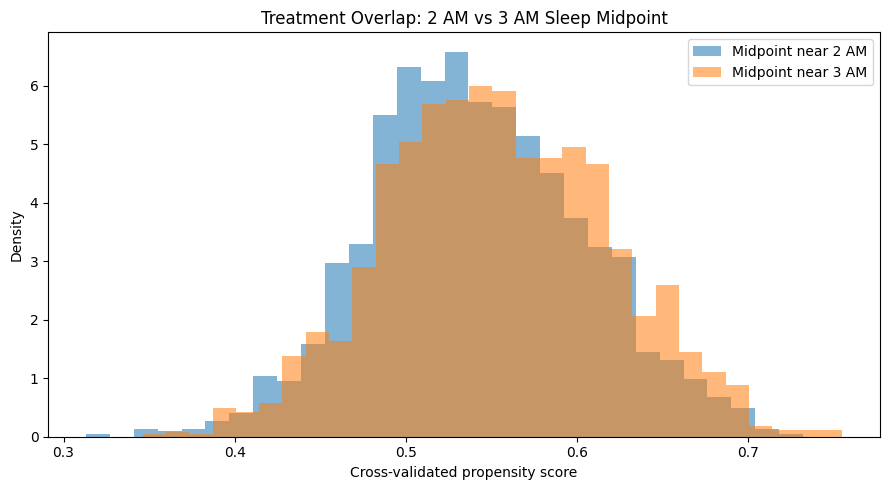

Outside [0.01, 0.99]: 0.0%
Outside [0.05, 0.95]: 0.0%
Outside [0.10, 0.90]: 0.0%

Saved overlap data and plot under outputs/causal_tests/


In [78]:
os.makedirs("outputs/causal_tests", exist_ok=True)

# --------------------------------------------------
# 1. DEFINE THE CAUSAL CONTRAST
# --------------------------------------------------

# Use the 2015-2016 development cycle.
causal_data = train.copy()

MIDPOINT = "sleep_midpoint_min"
OUTCOME = "LBXGH"

# Select the actual duration measurement, not a validity flag.
duration_candidates = [
    "sleep_duration_derived",
    "SLD012",
    "sleep_duration",
]

DURATION = next(
    (c for c in duration_candidates if c in causal_data.columns),
    None,
)

if MIDPOINT not in causal_data.columns:
    raise KeyError(
        f"{MIDPOINT} is missing. Available sleep columns: "
        f"{[c for c in causal_data.columns if 'sleep' in c.lower() or c.startswith('SL')]}"
    )

if OUTCOME not in causal_data.columns:
    raise KeyError(f"{OUTCOME} is missing.")

if DURATION is None:
    raise KeyError(
        "No actual sleep-duration column found. Inspect the available "
        "columns and set DURATION to the correct variable."
    )

# 2 AM = 120 minutes after midnight; 3 AM = 180.
midpoint = pd.to_numeric(causal_data[MIDPOINT], errors="coerce")

near_2am = midpoint.between(90, 150, inclusive="both")
near_3am = midpoint.between(150, 210, inclusive="both")

# Avoid assigning the shared 150-minute boundary to both groups.
near_2am = midpoint.between(90, 149.999, inclusive="both")
near_3am = midpoint.between(150, 210, inclusive="both")

causal_data["treatment"] = np.select(
    [near_2am, near_3am],
    [0, 1],
    default=np.nan,
)

causal_data["treatment"] = pd.to_numeric(
    causal_data["treatment"], errors="coerce"
)

causal_data[OUTCOME] = pd.to_numeric(
    causal_data[OUTCOME], errors="coerce"
)
causal_data[DURATION] = pd.to_numeric(
    causal_data[DURATION], errors="coerce"
)

# Keep only the two prespecified timing groups and observed outcome.
causal_data = causal_data.dropna(
    subset=["treatment", OUTCOME]
).copy()

causal_data["treatment"] = causal_data["treatment"].astype(int)

# --------------------------------------------------
# 2. PRESPECIFIED COVARIATES
# --------------------------------------------------

numeric_candidates = [
    "RIDAGEYR",
    "INDFMPIR",
    DURATION,
]

categorical_candidates = [
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
]

numeric_covars = [
    c for c in numeric_candidates
    if c in causal_data.columns
]

categorical_covars = [
    c for c in categorical_candidates
    if c in causal_data.columns
]

covariates = numeric_covars + categorical_covars

if len(covariates) == 0:
    raise ValueError("No adjustment covariates were found.")

# Do not include midpoint, HbA1c, or outcome-derived flags
# in the propensity model.
X_cov = causal_data[covariates].copy()
A = causal_data["treatment"].to_numpy()

print("=== CAUSAL CONTRAST ===")
print(f"Outcome: {OUTCOME}")
print(f"Exposure: {MIDPOINT}")
print(f"Duration adjustment: {DURATION}")
print(f"Adjustment covariates: {covariates}")
print("\nGroup counts:")
print(causal_data["treatment"].value_counts().sort_index().rename({
    0: "Near 2 AM",
    1: "Near 3 AM",
}))

# --------------------------------------------------
# 3. ESTIMATE PROPENSITY SCORES WITH CROSS-VALIDATION
# --------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            numeric_covars,
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore")),
            ]),
            categorical_covars,
        ),
    ],
    remainder="drop",
)

propensity_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        C=1.0,
    )),
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

propensity = cross_val_predict(
    propensity_model,
    X_cov,
    A,
    cv=cv,
    method="predict_proba",
)[:, 1]

causal_data["propensity"] = propensity

print("\n=== PROPENSITY SCORE SUMMARY ===")
print(
    causal_data.groupby("treatment")["propensity"]
    .agg(["count", "mean", "std", "min", "median", "max"])
)

print(
    "\nPropensity AUC:",
    round(roc_auc_score(A, propensity), 4),
)

# --------------------------------------------------
# 4. OVERLAP DIAGNOSTICS
# --------------------------------------------------

plt.figure(figsize=(9, 5))

for group, label in [(0, "Midpoint near 2 AM"), (1, "Midpoint near 3 AM")]:
    values = causal_data.loc[
        causal_data["treatment"] == group, "propensity"
    ]
    plt.hist(
        values,
        bins=30,
        alpha=0.55,
        density=True,
        label=label,
    )

plt.xlabel("Cross-validated propensity score")
plt.ylabel("Density")
plt.title("Treatment Overlap: 2 AM vs 3 AM Sleep Midpoint")
plt.legend()
plt.tight_layout()
plt.savefig(
    "outputs/causal_tests/propensity_overlap.png",
    dpi=200,
)
plt.show()

# Fraction of observations near propensity extremes.
for threshold in [0.01, 0.05, 0.10]:
    extreme = (
        (causal_data["propensity"] < threshold)
        | (causal_data["propensity"] > 1 - threshold)
    )
    print(
        f"Outside [{threshold:.2f}, {1-threshold:.2f}]: "
        f"{extreme.mean():.1%}"
    )

# --------------------------------------------------
# 5. SAVE AUDIT DATA
# --------------------------------------------------

causal_data.to_csv(
    "outputs/causal_tests/timing_contrast_overlap.csv",
    index=False,
)

print("\nSaved overlap data and plot under outputs/causal_tests/")

In [79]:
Y_COL = "LBXGH"
A_COL = "treatment"

numeric_covars = [
    c for c in ["RIDAGEYR", "INDFMPIR", "sleep_duration_derived"]
    if c in causal_data.columns
]

categorical_covars = [
    c for c in ["RIAGENDR", "RIDRETH3", "DMDEDUC2"]
    if c in causal_data.columns
]

covariates = numeric_covars + categorical_covars

dml_data = causal_data.dropna(
    subset=[Y_COL, A_COL]
).copy()

X = dml_data[covariates]
Y = dml_data[Y_COL].to_numpy(dtype=float)
A = dml_data[A_COL].to_numpy(dtype=float)

preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]),
        numeric_covars,
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ]),
        categorical_covars,
    ),
])

# Flexible nuisance models.
outcome_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.05,
        l2_regularization=1.0,
        random_state=42,
    )),
])

treatment_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", Ridge(alpha=1.0)),
])

def estimate_dml(X, A, Y, seed=42, n_splits=5):
    """Cross-fitted partially linear DML treatment-effect estimate."""
    X = X.reset_index(drop=True)
    A = np.asarray(A, dtype=float)
    Y = np.asarray(Y, dtype=float)

    n = len(Y)
    y_hat = np.zeros(n)
    a_hat = np.zeros(n)

    cv = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=seed,
    )

    for train_idx, valid_idx in cv.split(X):
        model_y = clone(outcome_model)
        model_a = clone(treatment_model)

        model_y.fit(X.iloc[train_idx], Y[train_idx])
        model_a.fit(X.iloc[train_idx], A[train_idx])

        y_hat[valid_idx] = model_y.predict(X.iloc[valid_idx])
        a_hat[valid_idx] = model_a.predict(X.iloc[valid_idx])

    y_resid = Y - y_hat
    a_resid = A - a_hat

    denominator = np.mean(a_resid ** 2)
    if denominator < 1e-8:
        raise ValueError("Residualized treatment variance is too small.")

    theta = np.mean(a_resid * y_resid) / denominator

    # Influence-function standard error.
    psi = a_resid * (y_resid - theta * a_resid)
    se = np.sqrt(np.mean(psi ** 2) / n) / denominator

    return {
        "ATE": theta,
        "SE": se,
        "CI_lower": theta - 1.96 * se,
        "CI_upper": theta + 1.96 * se,
        "n": n,
    }

# Observed estimate.
observed = estimate_dml(X, A, Y)

print("OBSERVED DML ESTIMATE")
print(pd.Series(observed).to_string())

# --------------------------------------------------
# PERMUTATION DIAGNOSTIC
# --------------------------------------------------

N_PERMUTATIONS = 200
rng = np.random.default_rng(42)
permutation_effects = []

for b in range(N_PERMUTATIONS):
    A_perm = rng.permutation(A)

    try:
        result = estimate_dml(
            X,
            A_perm,
            Y,
            seed=1000 + b,
        )
        permutation_effects.append(result["ATE"])
    except ValueError:
        continue

permutation_effects = np.asarray(permutation_effects)

if len(permutation_effects) == 0:
    raise RuntimeError("All permutation estimates failed.")

p_perm = (
    1 + np.sum(np.abs(permutation_effects) >= abs(observed["ATE"]))
) / (1 + len(permutation_effects))

print("\nPERMUTATION DIAGNOSTIC")
print(f"Successful permutations: {len(permutation_effects)}")
print(f"Observed effect: {observed['ATE']:.6f}")
print(f"Permutation mean: {permutation_effects.mean():.6f}")
print(f"Permutation SD: {permutation_effects.std(ddof=1):.6f}")
print(f"Two-sided permutation p-value: {p_perm:.4f}")

pd.DataFrame({
    "permutation_ATE": permutation_effects
}).to_csv(
    "outputs/causal_tests/exposure_permutation_results.csv",
    index=False,
)

OBSERVED DML ESTIMATE
ATE           -0.026766
SE             0.038703
CI_lower      -0.102624
CI_upper       0.049092
n           3510.000000

PERMUTATION DIAGNOSTIC
Successful permutations: 200
Observed effect: -0.026766
Permutation mean: -0.001153
Permutation SD: 0.039397
Two-sided permutation p-value: 0.5274


## Sensitivity Analysis

In [82]:
OUTCOME = "LBXGH"
MIDPOINT = "sleep_midpoint_min"
DURATION = "sleep_duration_derived"

BASE_COVARIATES = [
    "RIDAGEYR",
    "INDFMPIR",
    DURATION,
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
]

SEED = 42
N_SPLITS = 5

# --------------------------------------------------
# PREPARE DATA
# --------------------------------------------------
df = train.copy()

required = [OUTCOME, MIDPOINT] + BASE_COVARIATES
df = df.dropna(subset=[OUTCOME, MIDPOINT]).copy()

# Keep the two groups mutually exclusive.
def assign_treatment(midpoint, window):
    center_2am = 120
    center_3am = 180

    near_2 = (
        (midpoint >= center_2am - window)
        & (midpoint < center_2am + window)
    )
    near_3 = (
        (midpoint >= center_3am - window)
        & (midpoint <= center_3am + window)
    )

    a = pd.Series(np.nan, index=midpoint.index)
    a.loc[near_2] = 0
    a.loc[near_3] = 1
    return a

# --------------------------------------------------
# DML ESTIMATOR
# --------------------------------------------------
def make_preprocessor(X):
    numeric = X.select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in X.columns if c not in numeric]

    transformers = []

    if numeric:
        transformers.append((
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scale", StandardScaler()),
            ]),
            numeric,
        ))

    if categorical:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                )),
            ]),
            categorical,
        ))

    return ColumnTransformer(transformers, remainder="drop")


def estimate_dml(data, covariates, outcome_model, treatment_model,
                 seed=SEED, n_splits=N_SPLITS):
    cols = covariates + [OUTCOME, "treatment"]
    d = data[cols].dropna(subset=[OUTCOME, "treatment"]).copy()

    X = d[covariates]
    y = d[OUTCOME].to_numpy(dtype=float)
    a = d["treatment"].to_numpy(dtype=int)

    if len(np.unique(a)) != 2:
        raise ValueError("Both treatment groups must be represented.")

    y_hat = np.full(len(d), np.nan)
    a_hat = np.full(len(d), np.nan)

    cv = KFold(n_splits=n_splits, shuffle=True, random_state=seed)

    for tr_idx, te_idx in cv.split(X):
        X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
        y_tr, a_tr = y[tr_idx], a[tr_idx]

        prep = make_preprocessor(X_tr)

        y_pipe = Pipeline([
            ("preprocessor", clone(prep)),
            ("model", clone(outcome_model)),
        ])
        a_pipe = Pipeline([
            ("preprocessor", clone(prep)),
            ("model", clone(treatment_model)),
        ])

        y_pipe.fit(X_tr, y_tr)
        a_pipe.fit(X_tr, a_tr)

        y_hat[te_idx] = y_pipe.predict(X_te)
        a_hat[te_idx] = a_pipe.predict_proba(X_te)[:, 1]

    # Partially linear DML score
    y_resid = y - y_hat
    a_resid = a - a_hat
    denominator = np.mean(a_resid ** 2)

    if denominator < 1e-8:
        raise ValueError("Insufficient residual treatment variation.")

    theta = np.mean(a_resid * y_resid) / denominator

    # Conventional IID influence-function SE; does not account
    # for NHANES survey design.
    psi = a_resid * (y_resid - theta * a_resid)
    se = np.sqrt(np.mean(psi ** 2) / len(d)) / denominator

    return {
        "ATE": theta,
        "SE": se,
        "CI_lower": theta - 1.96 * se,
        "CI_upper": theta + 1.96 * se,
        "n": len(d),
        "n_control": int(np.sum(a == 0)),
        "n_treated": int(np.sum(a == 1)),
        "propensity_min": float(np.min(a_hat)),
        "propensity_max": float(np.max(a_hat)),
    }


# --------------------------------------------------
# SENSITIVITY SPECIFICATIONS
# --------------------------------------------------
# All variables must be available in the dataset.
covariate_sets = {
    "Base": BASE_COVARIATES,
    "Demographics_only": [
        "RIDAGEYR", "INDFMPIR", "RIAGENDR", "RIDRETH3", "DMDEDUC2"
    ],
    "Demographics_plus_duration": BASE_COVARIATES,
    "Age_sex_duration": [
        "RIDAGEYR", "RIAGENDR", DURATION
    ],
    "Age_income_duration": [
        "RIDAGEYR", "INDFMPIR", DURATION
    ],
}

model_pairs = {
    "Ridge_Logistic": (
        Ridge(alpha=10.0),
        LogisticRegression(C=1.0, max_iter=2000, random_state=SEED),
    ),
    "ExtraTrees_Logistic": (
        ExtraTreesRegressor(
            n_estimators=200, min_samples_leaf=10,
            random_state=SEED, n_jobs=-1,
        ),
        LogisticRegression(C=1.0, max_iter=2000, random_state=SEED),
    ),
    "HistGB_Logistic": (
        HistGradientBoostingRegressor(
            max_iter=150, learning_rate=0.05,
            l2_regularization=1.0, random_state=SEED,
        ),
        LogisticRegression(C=1.0, max_iter=2000, random_state=SEED),
    ),
    "Ridge_ExtraTreesClassifier": (
        Ridge(alpha=10.0),
        ExtraTreesClassifier(
            n_estimators=200, min_samples_leaf=10,
            random_state=SEED, n_jobs=-1,
        ),
    ),
}

# Baseline window: ±30 minutes around 2 AM and 3 AM.
# Additional windows check sensitivity to group definitions.
windows = {
    "±20_min": 20,
    "±30_min": 30,
    "±40_min": 40,
}

results = []

for window_name, window in windows.items():
    window_data = df.copy()
    window_data["treatment"] = assign_treatment(
        window_data[MIDPOINT], window
    )
    window_data = window_data.dropna(subset=["treatment"]).copy()
    window_data["treatment"] = window_data["treatment"].astype(int)

    for cov_name, covariates in covariate_sets.items():
        for model_name, (y_model, a_model) in model_pairs.items():
            try:
                result = estimate_dml(
                    window_data,
                    covariates,
                    y_model,
                    a_model,
                    seed=SEED,
                    n_splits=N_SPLITS,
                )
                results.append({
                    "Window": window_name,
                    "Adjustment": cov_name,
                    "Nuisance_models": model_name,
                    **result,
                })
            except Exception as e:
                results.append({
                    "Window": window_name,
                    "Adjustment": cov_name,
                    "Nuisance_models": model_name,
                    "error": str(e),
                })

sensitivity = pd.DataFrame(results)

from pathlib import Path

out_dir = Path("outputs/causal_tests")
out_dir.mkdir(parents=True, exist_ok=True)

sensitivity.to_csv(
    out_dir / "dml_sensitivity_analysis.csv", index=False
)

valid = sensitivity[sensitivity["ATE"].notna()].copy()
print(valid[[
    "Window", "Adjustment", "Nuisance_models",
    "ATE", "SE", "CI_lower", "CI_upper",
    "n", "n_control", "n_treated",
]].to_string(index=False))

print(f"\nSaved to {out_dir / 'dml_sensitivity_analysis.csv'}")

 Window                 Adjustment            Nuisance_models       ATE       SE  CI_lower  CI_upper    n  n_control  n_treated
±20_min                       Base             Ridge_Logistic -0.044870 0.047124 -0.137233  0.047493 2137       1135       1002
±20_min                       Base        ExtraTrees_Logistic -0.031944 0.046777 -0.123626  0.059739 2137       1135       1002
±20_min                       Base            HistGB_Logistic -0.030258 0.048379 -0.125082  0.064565 2137       1135       1002
±20_min                       Base Ridge_ExtraTreesClassifier -0.038892 0.046677 -0.130379  0.052594 2137       1135       1002
±20_min          Demographics_only             Ridge_Logistic -0.047557 0.046984 -0.139645  0.044532 2137       1135       1002
±20_min          Demographics_only        ExtraTrees_Logistic -0.027573 0.046619 -0.118947  0.063801 2137       1135       1002
±20_min          Demographics_only            HistGB_Logistic -0.024239 0.047981 -0.118283  0.069805 213